# 01 — The survey's taxonomy, our systems on it, and the agent's process

Part 1 places the Block 3 systems on the survey's map (Singh et al., v4 2026, Table 3).
Part 2 reads the process metrics written by `make b4` (`results/process_metrics.csv`) and replays
one agent trace with `ragbench.b4`. No LLM is called.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from ragbench import b4

R = Path("../results")
B3 = Path("../../03-system-design/results/evaluation")

## 1. The survey's Table 3 (transcribed from v4, section 9.1)

Qualitative ratings by the authors, not measurements. They are a checklist of questions to ask
about a design.

In [2]:
table3 = pd.DataFrame({
    "single-agent": ["single", "centralized", "unstructured", "low", "implicit, LLM-driven",
                     "low to moderate", "limited", "moderate", "low", "low", "simple QA and routing"],
    "multi-agent": ["multiple", "flat", "unstructured or hybrid", "moderate", "distributed across agents",
                    "moderate to high", "high", "high", "moderate", "moderate", "multi-domain synthesis"],
    "hierarchical / corrective": ["multiple (tiered)", "hierarchical / evaluator-based", "unstructured or hybrid",
                                  "moderate", "strategic, supervisory control", "high", "high", "moderate",
                                  "high", "high", "high-stakes, reliability-critical"],
    "graph / document-centric": ["multiple", "adaptive / structured", "graph-based or document-centric",
                                 "high, sensitive to graph quality", "relational or symbolic + LLM",
                                 "high, multi-hop", "high", "moderate", "moderate to high", "high",
                                 "knowledge-intensive, relational"],
}, index=["agent cardinality", "control structure", "knowledge representation", "knowledge dependency",
          "reasoning mode", "reasoning depth", "retrieval adaptivity", "scalability", "latency",
          "engineering complexity", "best-fit scenarios"])
table3

,single-agent,multi-agent,hierarchical / corrective,graph / document-centric
agent cardinality,single,multiple,multiple (tiered),multiple
control structure,centralized,flat,hierarchical / evaluator-based,adaptive / structured
knowledge representation,unstructured,unstructured or hybrid,unstructured or hybrid,graph-based or document-centric
knowledge dependency,low,moderate,moderate,"high, sensitive to graph quality"
reasoning mode,"implicit, LLM-driven",distributed across agents,"strategic, supervisory control",relational or symbolic + LLM
reasoning depth,low to moderate,moderate to high,high,"high, multi-hop"
retrieval adaptivity,limited,high,high,high
scalability,moderate,high,moderate,moderate
latency,low,moderate,high,moderate to high
engineering complexity,low,moderate,high,high


## 2. Our Block 3 systems, described on the same dimensions

Our own description (section 7 of the course), with one row the survey's table lacks: autonomy.

In [3]:
ours = pd.DataFrame({
    "fixed": ["none (workflow)", "fixed chain", "none", "unstructured chunks", "1 LLM call"],
    "agentic": ["single", "centralized, LLM-driven", "bounded: 6 tool calls, 8,000 tokens",
                "unstructured chunks, chunk and page granularity", "tool use"],
    "cascade": ["single, conditional", "rule-based routing", "none in the router",
                "unstructured chunks", "routing + tool use"],
}, index=["agent cardinality", "control structure", "autonomy", "knowledge representation", "patterns"])
ours

,fixed,agentic,cascade
agent cardinality,none (workflow),single,"single, conditional"
control structure,fixed chain,"centralized, LLM-driven",rule-based routing
autonomy,none,"bounded: 6 tool calls, 8,000 tokens",none in the router
knowledge representation,unstructured chunks,"unstructured chunks, chunk and page granularity",unstructured chunks
patterns,1 LLM call,tool use,routing + tool use


## 3. Process metrics of the Block 3 agent (`make b4`)

Exploratory (protocol `configs/b4_process_metrics.yaml`, written before computing, after the traces
had been read). Shares are over calls of the relevant type.

In [4]:
process = pd.read_csv(R / "process_metrics.csv").set_index("group")
process.T.round(3)

group,all,stop=done,stop=tool_budget
questions,100.000,71.000,29.000
tool_calls_mean,4.910,4.465,6.000
calls_keyword_search,103.000,72.000,31.000
calls_semantic_search,90.000,52.000,38.000
calls_chunk_read,229.000,139.000,90.000
calls_page_read,67.000,52.000,15.000
calls_invalid,2.000,2.000,0.000
empty_read_share,0.807,0.775,0.867
reread_of_initial_share,0.969,0.971,0.967
search_without_new_candidate_share,0.228,0.234,0.217


## 4. Where the tool calls go

Each bar splits the agent's calls by what they achieved: searches that surfaced at least one new
candidate, searches that did not, reads that added evidence, reads that added nothing, invalid calls.

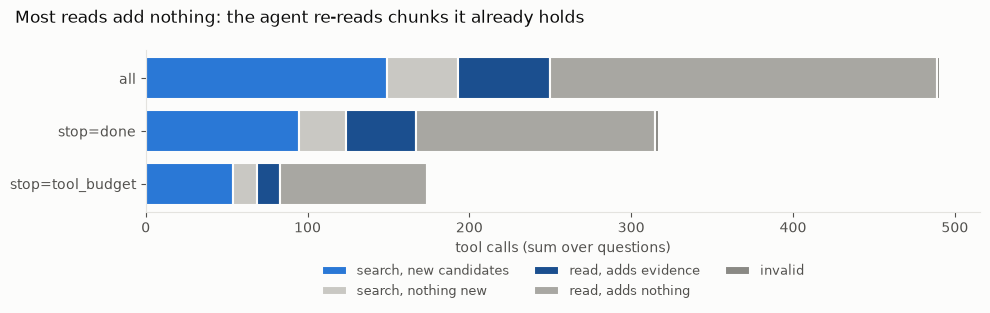

In [5]:
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
USEFUL, WASTED, INVALID = "#2a78d6", "#c9c8c3", "#8a8984"
rows = []
for group, r in process.iterrows():
    searches = r.calls_keyword_search + r.calls_semantic_search
    reads = r.calls_chunk_read + r.calls_page_read
    rows.append({
        "group": group,
        "search, new candidates": searches * (1 - r.search_without_new_candidate_share),
        "search, nothing new": searches * r.search_without_new_candidate_share,
        "read, adds evidence": reads * (1 - r.empty_read_share),
        "read, adds nothing": reads * r.empty_read_share,
        "invalid": r.calls_invalid,
    })
calls = pd.DataFrame(rows).set_index("group")
colors = [USEFUL, WASTED, "#1b4f8f", "#a8a7a2", INVALID]
fig, ax = plt.subplots(figsize=(10, 3.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
left = pd.Series(0.0, index=calls.index)
for col, color in zip(calls.columns, colors):
    ax.barh(calls.index, calls[col], left=left, color=color, label=col, edgecolor=SURFACE, linewidth=1.5)
    left += calls[col]
ax.invert_yaxis()
ax.set_xlabel("tool calls (sum over questions)", color=INK2)
ax.tick_params(colors=INK2)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(GRID)
ax.legend(ncol=3, frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.25),
          labelcolor=INK2)
fig.suptitle("Most reads add nothing: the agent re-reads chunks it already holds", color=INK,
             x=0.02, ha="left")
fig.tight_layout()

## 5. Replaying one trace

The question the agent lost in Block 3 (notebook 01 of Block 3): six calls, one useful.

In [6]:
rows = {r["qid"]: r for r in map(json.loads, (B3 / "agentic.jsonl").open())}
row = rows["ABMD/2008/page_86.pdf-4"]
initial = row["context"][: len(row["context"]) - row["added_chunks"]]
pool = set(initial)
for n, s in enumerate(row["trace"], start=1):
    new = [i for i in s["results"] if i not in pool] if s["tool"] in b4.SEARCHES else s["added"]
    already = "  (in the initial top-10)" if s["tool"] == "chunk_read" and set(s["results"]) <= set(initial) else ""
    print(f"{n}. {s['tool']:16s} results={s['results']}  new={new}{already}")
    pool |= set(s["added"])
b4.process_metrics(row["trace"], initial)

1. keyword_search   results=[157, 158, 1596, 159, 1597]  new=[]
2. chunk_read       results=[158]  new=[]  (in the initial top-10)
3. chunk_read       results=[157]  new=[]  (in the initial top-10)
4. semantic_search  results=[158, 159, 157, 1596, 1597]  new=[]
5. chunk_read       results=[159]  new=[]  (in the initial top-10)
6. page_read        results=[155, 156, 157, 158, 159]  new=[155, 156]


{'calls_keyword_search': 1,
 'calls_semantic_search': 1,
 'calls_chunk_read': 3,
 'calls_page_read': 1,
 'calls_invalid': 0,
 'tool_calls': 6,
 'empty_read': 3,
 'reread_of_initial': 3,
 'search_without_new_candidate': 2,
 'chunks_added': 2}